In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import random

In [20]:
from features import limpiar_features_no_necesarias, transformar_features, transformar_target_a_estrellas
from graficos import plot_boxplot_rating_por_genero, plot_generos_mas_frecuentes, plot_rating, plot_rating_por_genero, plot_stars, plot_boxplot_rating, plot_cantidad_generos_por_libro

## 1. ABRIENDO DATASET ORIGINAL

"""features que podemos volar
- isbn: podemos eliminar? o nos sirve para el mini recomendador
- text_reviews count: ok
- series: transformar a is_standalone -> booleano
- country_code: hacer one hot encoding sobre si esta en US o no
- language_code: 
- popular_shelves: 
- asin: volar 
- is_ebook: graficar y ver si esto tiene impacto o no
- average_rating: target
- kindle_asin: volar
- similar_books: es hacer trampa?
- description: ver como tratarla
- format: transformarlo con one hot encoding
- publication_month: volar
- publication_year: lo dejamos asi
- url: no se si nos sirve, tal vez para despues. diria que volar
- image_url: volar
- book_id: ni idea
- ratings count: dejar asi
- work id: volar
- titulo: nos lo quedamos asi pero no lo usamos para el entrenamiento
- title_without_series: volar, nos quedamos solo con el titulo
- authors: es un diccionario: como lo tratamos
- publisher: transformar a bool de si tiene publisher o no?
- num_pages: nos lo quedamos asi
- publication_day: volar
- isbn13: volar


### 1.1 Chusmeando un poco

### 1.2 Otra forma de abrirlo (aleatorio)

In [21]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)

print(df.shape)
print(df.head())

(100000, 29)
         isbn text_reviews_count    series country_code language_code  \
0                              2        []           US           eng   
1  1561841641                  9  [258555]           US         en-US   
2                              2        []           US           eng   
3  1612624065                  7  [693052]           US           eng   
4  0170050688                  1        []           US                 

                                     popular_shelves asin is_ebook  \
0  [{'count': '107', 'name': 'currently-reading'}...          true   
1  [{'count': '166', 'name': 'to-read'}, {'count'...         false   
2  [{'count': '77', 'name': 'to-read'}, {'count':...         false   
3  [{'count': '435', 'name': 'manga'}, {'count': ...         false   
4  [{'count': '2', 'name': 'to-read'}, {'count': ...         false   

  average_rating kindle_asin  \
0           4.18               
1           4.07               
2           4.90               

In [22]:
for i in range(5):
    print(f"Libro {i}")
    print(df["popular_shelves"].iloc[i])
    print()

from collections import Counter

counter = Counter()

for shelves in df["popular_shelves"]:
    for shelf in shelves:
        counter[shelf["name"]] += 1
counter.most_common(200)

Libro 0
[{'count': '107', 'name': 'currently-reading'}, {'count': '80', 'name': 'to-read'}, {'count': '6', 'name': 'historical-romance'}, {'count': '3', 'name': 'kindle'}, {'count': '2', 'name': 'historical'}, {'count': '2', 'name': 'dnf'}, {'count': '2', 'name': 'gothic'}, {'count': '2', 'name': 'critique-group'}, {'count': '1', 'name': 'romance'}, {'count': '1', 'name': 'historical-standalones'}, {'count': '1', 'name': 'waiting-on-kindle-bought'}, {'count': '1', 'name': 'read-sample'}, {'count': '1', 'name': 'not-interested'}, {'count': '1', 'name': 'zshelf-e'}, {'count': '1', 'name': 'maybe-maybe-not'}, {'count': '1', 'name': '01-books'}, {'count': '1', 'name': 'romance-regency-victorian-jacobite'}, {'count': '1', 'name': 'romance-mild'}, {'count': '1', 'name': 'romance-historical-gothic'}, {'count': '1', 'name': 'romance-class-differences'}, {'count': '1', 'name': 'romance-books'}, {'count': '1', 'name': 'historical-fiction'}, {'count': '1', 'name': 'widower'}, {'count': '1', 'name

[('to-read', 95858),
 ('currently-reading', 71492),
 ('owned', 44758),
 ('fiction', 42454),
 ('favorites', 40740),
 ('kindle', 37586),
 ('books-i-own', 36825),
 ('ebook', 32114),
 ('library', 31112),
 ('default', 30047),
 ('owned-books', 25842),
 ('to-buy', 25181),
 ('romance', 24822),
 ('ebooks', 24579),
 ('wish-list', 23733),
 ('series', 22560),
 ('non-fiction', 20554),
 ('contemporary', 20222),
 ('adult', 20037),
 ('fantasy', 17964),
 ('my-books', 17768),
 ('e-book', 16846),
 ('books', 16843),
 ('my-library', 16500),
 ('audiobook', 16313),
 ('mystery', 15646),
 ('nonfiction', 15195),
 ('audiobooks', 15132),
 ('i-own', 15005),
 ('audio', 14615),
 ('read-in-2016', 14022),
 ('e-books', 13872),
 ('history', 13433),
 ('read-in-2017', 12982),
 ('read-in-2015', 12914),
 ('novels', 12873),
 ('historical', 12427),
 ('maybe', 12262),
 ('favourites', 12234),
 ('own-it', 12064),
 ('young-adult', 12017),
 ('historical-fiction', 11613),
 ('abandoned', 11303),
 ('adult-fiction', 11019),
 ('read-in

In [23]:
from features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)
sin_genero = (df["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero/len(df):.2f}%")

Porcentaje de libros sin genero: 12.23%


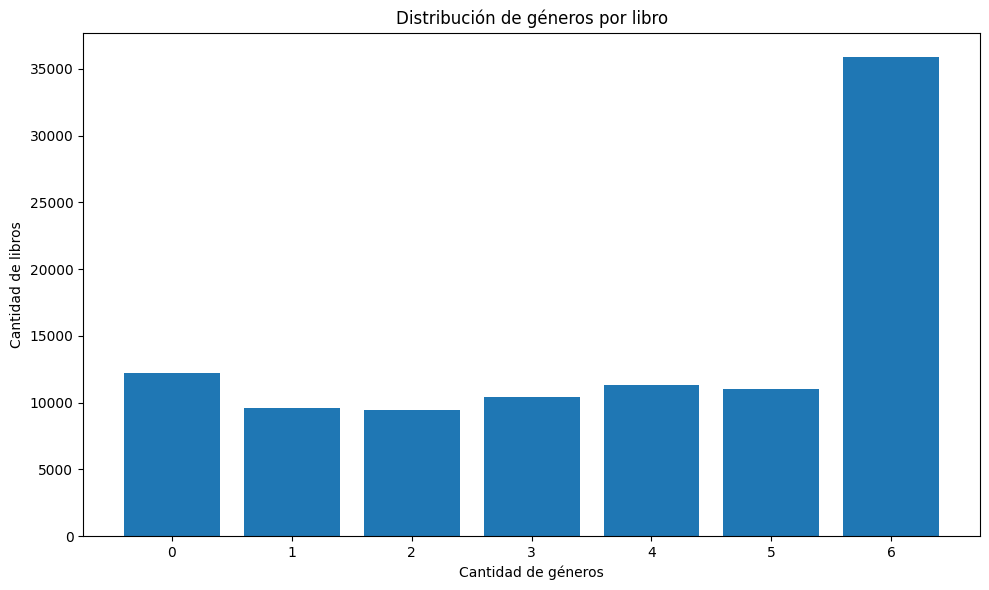

In [24]:
plot_cantidad_generos_por_libro(df)

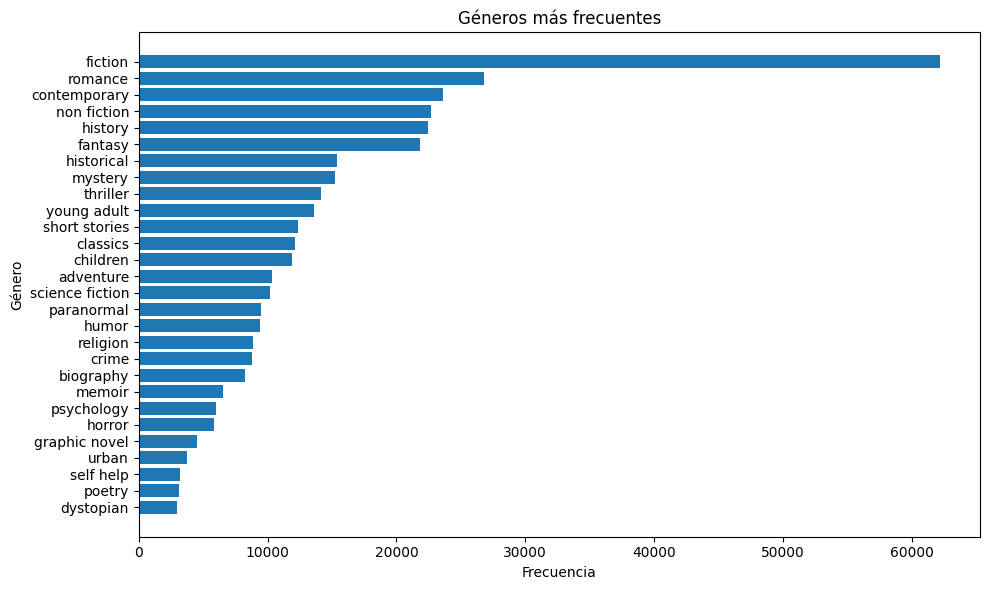

In [25]:
contador_generos = (df["genres"].explode().value_counts()) #.explode() separa los elementos de la lista
plot_generos_mas_frecuentes(contador_generos)

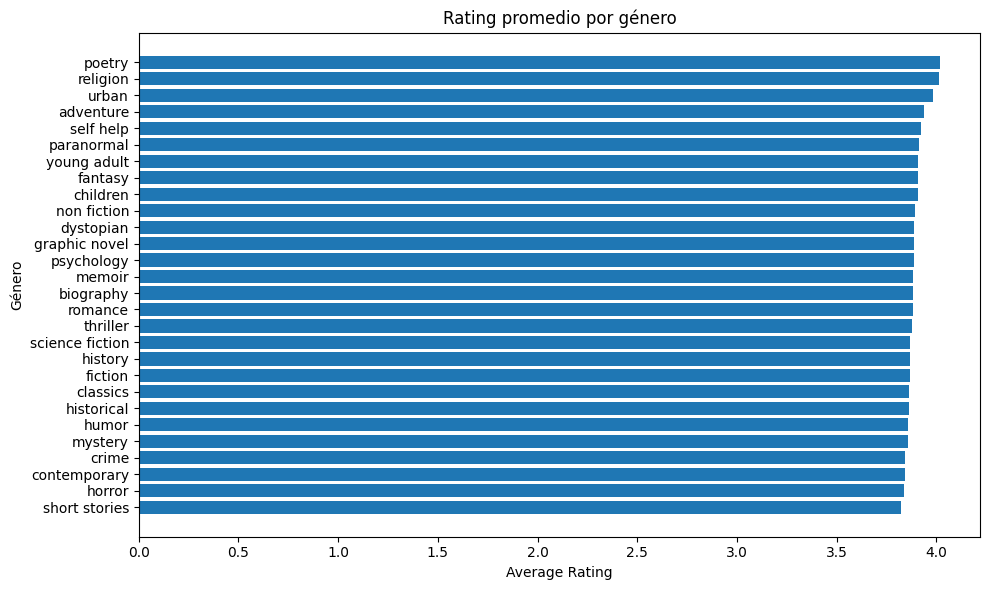

In [26]:
df["average_rating"] = pd.to_numeric(df["average_rating"],errors="coerce")
plot_rating_por_genero(df)

<Figure size 1200x600 with 0 Axes>

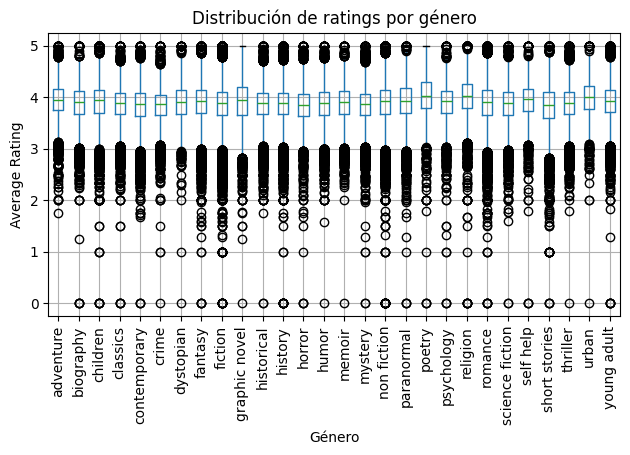

In [27]:
plot_boxplot_rating_por_genero(df)

# Agregar al otro notebook

In [ ]:
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer

In [33]:
#funciones sacadas de otro archivo y modificadas un poco

def es_parte_de_saga(series):
    #la feature series contiene una lista vacia si es un standalone, o un codigo si es parte de una saga
    return len(series) > 0

#SACADO DEL EDA:
def normalize_format(value):
    #Si el valor no es un string:
    if not isinstance(value, str):
        return "UNKNOWN"
    #Si no hay un valor para la muestra o es un espacio en blanco:
    s = value.strip().lower()
    if s == "":
        return "UNKNOWN"
    if "unknown binding" in s or s == "unknown":
        return "UNKNOWN"

    #Reemplazamos &amp; (código HTML para &) por solo &:
    s = s.replace("&amp;", "&")

    #Hacemos unas correcciones de cosas que aparecen frecuentemente en el dataset:
    s = s.replace("papperback", "paperback")
    s = s.replace("papaerback", "paperback")
    s = s.replace("paberback", "paperback")
    s = s.replace("hardcovver", "hardcover")
    s = s.replace("hardover", "hardcover")
    s = s.replace("harcover", "hardcover")


    #Ebook (digital)
    ebook_terms = [
        "ebook", "e-book", "e book", "kindle", "nook", "nookbook", "ibook", "epub", "pdf", "electronic",
        "digital", "online", "wattpad", "webtoon", "webcomic", "web comic", "online fiction", "online fanfiction",
        "free online fiction", "free online read", "online read", "online serial", "online publication", "digital comic",
        "fanfiction"
    ]

    #Formato de audios
    audio_terms = [
        "audio", "audiobook", "audible", "audio cd", "audio cassette", "audio book",
        "audio play", "audio lecture", "audio podcast", "mp3", "cd audio", "cassette",
        "playaway", "digital audio", "overdrive audio"
    ]

    #Hardcover (hardback)
    hardcover_terms = [
        "hardcover", "hard cover", "hardback", "hardbound", "hard bound", "casebound", "library binding",
        "school binding", "cloth bound", "clothbound", "leather bound", "leatherbound", "slipcased",
        "slipcase", "flexbound", "hardcover with slipcase"
    ]

    #Paperback (softcover)
    paperback_terms = [
        "paperback", "softcover", "soft cover", "trade paperback", "mass market paperback", "paper back",
        "paperbound", "pocket paperback", "capa mole", "brochura", "broche", "brochure", "brossura", "paperback with dvd",
        "paperback with flaps", "paperback (large print)", "perfect paperback", "mass paperback", "softback",
        "quality paperback", "paperback manga", "spiral-bound", "spiral bound", "chapbook", "paper", 
    ]

    #Comic / manga / graphic
    comic_terms = ["comic", "graphic novel", "manga", "comic book", "graphic", "manhwa", "manhua", "fancomic"]

    if any(term in s for term in audio_terms):
        return "AUDIO"

    if any(term in s for term in comic_terms):
        return "COMIC"

    if any(term in s for term in hardcover_terms):
        return "HARDCOVER"

    if any(term in s for term in paperback_terms):
        return "PAPERBACK"

    if any(term in s for term in ebook_terms):
        return "EBOOK"

    return "OTHER"


def transformar_features(df):
    #Comento ciertas lienas porque esta funcion se tendria que aplica rluego del EDA, y:
        #is_seriess --> nos sirve hacerlo antes de eda para hacer un buen analisis de su relacion con el target
        #is_ebook --> no vamos a necesitar hacerlo porque la vamos a eliminar (redundancia con el one-hot de format_group)
        #La de reagrupa format --> ya lo hago antes del EDA

    #is_series: feature binaria, true si es parte de una saga
    df["is_series"] = df["series"].apply(es_parte_de_saga)
    df = df.drop(columns = ["series"])

    #format: una vez habiendo simplificado los formatos, aplicamos one hot encoding
    df["format"] = df["format"].apply(normalize_format)
    encoder_format = OneHotEncoder(sparse_output=False)
    encoded_format = encoder_format.fit_transform(df[['format']])
    encoded_df = pd.DataFrame(encoded_format, columns = encoder_format.get_feature_names_out(["format"]), index = df.index)
    df = df.join(encoded_df)
    #publication_year, num_pages: transformar a numero (estaban en formato string) #TODO: eliminar o ver como imputar nan
    df["publication_year"] = pd.to_numeric(df["publication_year"], errors='coerce')
    df["num_pages"] = pd.to_numeric(df["num_pages"], errors='coerce')
    return df

In [34]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

#"one hot multiclase" para la feature genres
mlb = MultiLabelBinarizer()
genres_encoded = mlb.fit_transform(df["genres"])
genres_df = pd.DataFrame(genres_encoded, columns=mlb.classes_, index=df.index)
df = df.join(genres_df)

generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series","is_ebook","publication_year","num_pages","format_AUDIO","format_COMIC","format_EBOOK","format_HARDCOVER","format_OTHER","format_PAPERBACK","format_UNKNOWN",] + generos

#hago one hot de genero
df_nuevo = transformar_features(df)

#correlacion con el target
corr_rating = (df_nuevo[features + ["average_rating"]].corr(numeric_only=True)["average_rating"].sort_values())

plt.figure(figsize=(8, max(8, len(corr_rating) * 0.3)))
sns.heatmap(corr_rating.to_frame(),annot=True,cmap="coolwarm",center=0,fmt=".2f")
plt.title("Correlación de las features con average_rating")
plt.tight_layout()
plt.show()

ValueError: columns overlap but no suffix specified: Index(['adventure', 'biography', 'children', 'classics', 'contemporary',
       'crime', 'dystopian', 'fantasy', 'fiction', 'graphic novel',
       'historical', 'history', 'horror', 'humor', 'memoir', 'mystery',
       'non fiction', 'paranormal', 'poetry', 'psychology', 'religion',
       'romance', 'science fiction', 'self help', 'short stories', 'thriller',
       'urban', 'young adult'],
      dtype='object')

Por si solas, estas features no aportan mucha informacion al modelo. Sin embargo, podemos intentar con algunas combinaciones:
- young adult * romance
- young adult * fantasy
- mystery * thriller
- len(generos)

# 3. Analisis del target

In [ ]:
df["average_rating"] = pd.to_numeric(df["average_rating"], errors='coerce')
print(df["average_rating"].isna().sum())
print(df["average_rating"].max())
print(df["average_rating"].min())

0
5.0
0.0


En este sample, hay 21 libros sin rating. Corresponde al 0.021%. Podemos eliminar esos libros. Notamos aparte que no hay outliers. 

In [ ]:
df = df.dropna(subset=["average_rating"])
target_regresion = df["average_rating"]
df["estrellas"] = transformar_target_a_estrellas(target_regresion)

Como lo van a confirmar los graficos mas adelante, la mayoria de ratings se encuentran entre 3.5 y 4.5. 

In [ ]:
df["estrellas"].value_counts(normalize=True).sort_index()

estrellas
0    0.00266
1    0.00182
2    0.01103
3    0.14368
4    0.76392
5    0.07689
Name: proportion, dtype: float64

El desbalanceo de clases se hace aun mas presente en el target para clasificacion.

In [ ]:
target_clasificacion_balanceado = pd.qcut(df["average_rating"], q=5)
print(target_clasificacion_balanceado.value_counts().sort_index())

average_rating
(-0.001, 3.54]    20165
(3.54, 3.81]      20513
(3.81, 4.0]       21534
(4.0, 4.23]       18057
(4.23, 5.0]       19710
Name: count, dtype: int64


Esta estrategia permitiria mantener 5 clases balanceadas, pero perdemos la interpretabilidad de las 5 estrellas. 

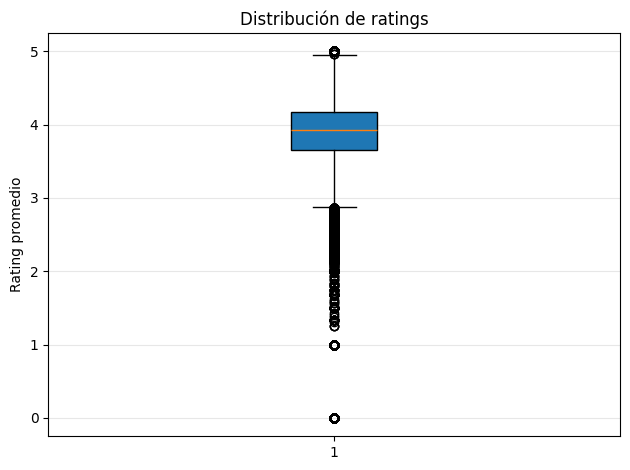

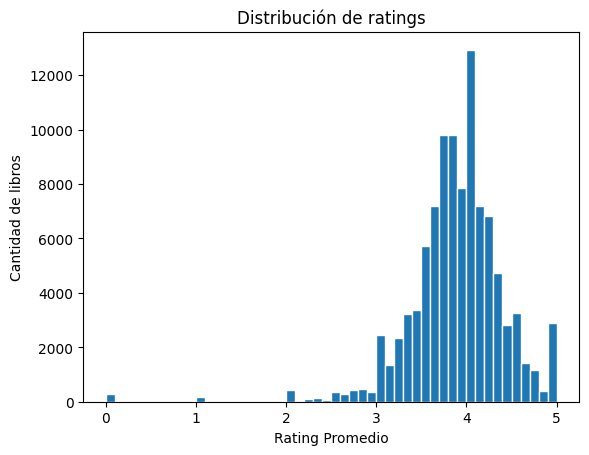

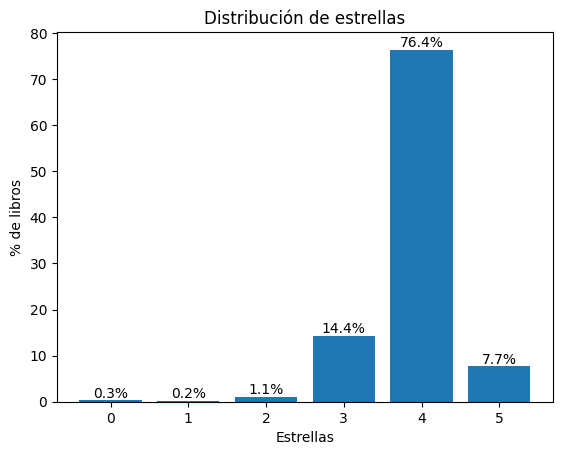

In [ ]:
plot_boxplot_rating(df)
plot_rating(df)
plot_stars(df)